In [1]:
import numpy as np
import torch
from torchvision import datasets, transforms
from tqdm import tqdm
import matplotlib.pyplot as plt
import torch.nn.functional as F

# Загрузка MNIST

In [2]:
mnist_train = datasets.MNIST(
    root='./datasets',
    train=True,
    transform=transforms.ToTensor(),
    download=True
)

mnist_train.data.shape

100%|██████████| 9.91M/9.91M [00:05<00:00, 1.73MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 185kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.36MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 1.48MB/s]


torch.Size([60000, 28, 28])

In [3]:
mnist_test = datasets.MNIST(
    root='./datasets',
    train=False,
    transform=transforms.ToTensor(),
    download=True
)
mnist_test.data.shape

torch.Size([10000, 28, 28])

In [4]:
image, label = mnist_train[3]
image.shape

torch.Size([1, 28, 28])

In [5]:
image = image.reshape([28, 28])
image.shape

torch.Size([28, 28])

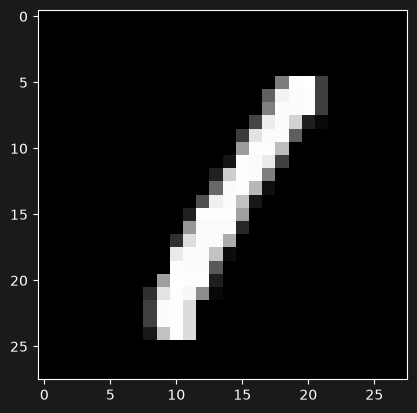

Label: 1


In [6]:
plt.imshow(image, cmap='gray')
plt.show()
print(f'Label: {label}')

In [7]:
train_loader = torch.utils.data.DataLoader(
    dataset=mnist_train,
    batch_size=100,
    shuffle=True
)

test_loader = torch.utils.data.DataLoader(
    dataset=mnist_test,
    batch_size=100,
    shuffle=False
)

In [8]:
data_train_iter = iter(train_loader)
images, labels = next(data_train_iter)
print(images.shape)
print(labels.shape)

torch.Size([100, 1, 28, 28])
torch.Size([100])


In [9]:
x = images.view(-1, 28*28)
print(x.shape)

torch.Size([100, 784])


$$
y_1 = \sum_i x_iw_{i,1} = b_1
$$

$$
y = zW + b
$$

In [10]:
W = torch.randn(784, 10) / np.sqrt(784) # Xavier initialization

$$
\sigma = \frac{1}{\sqrt{784}}
$$

[XE VS HE habr](https://habr.com/ru/articles/932852/)

[Xavier in Geeksforgeeks](https://www.geeksforgeeks.org/deep-learning/xavier-initialization/)

[XE VS HE medium](https://medium.com/thedeephub/he-and-xavier-weight-initialization-functions-acedc5322ce5)



In [11]:
W.requires_grad = True
b = torch.zeros(10, requires_grad=True)
W, b

(tensor([[ 0.0069, -0.0246, -0.0594,  ..., -0.0369,  0.0060,  0.0292],
         [ 0.0145,  0.0106,  0.0201,  ...,  0.0546,  0.0333, -0.0487],
         [ 0.0109,  0.0219,  0.0143,  ..., -0.0038, -0.0657,  0.0424],
         ...,
         [ 0.0493,  0.0066,  0.0309,  ..., -0.0410, -0.0251, -0.0214],
         [ 0.0328,  0.0005,  0.0030,  ...,  0.0101, -0.0289,  0.1019],
         [ 0.0451,  0.0319,  0.0106,  ..., -0.0847,  0.0310, -0.0297]],
        requires_grad=True),
 tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0.], requires_grad=True))

# Forward propagation
$$
y = xW +b
$$

In [12]:
y = torch.matmul(x, W) + b
print(y[0, :])

tensor([-0.0215,  0.1737, -0.1089, -0.2246,  0.1454, -0.1419, -0.4864, -0.0838,
        -0.3146,  0.1707], grad_fn=<SelectBackward0>)


# Softmax

$$
P_i = \frac{e^{z_i}}{\sum_{j=1}^10e^{z_j}}
$$

In [13]:
# py_eq = torch.exp(y)/torch.sum(torch.exp(y), dim=1, keepdim=True)
# print(py_eq[0])

tensor([0.1048, 0.1274, 0.0960, 0.0855, 0.1238, 0.0929, 0.0658, 0.0985, 0.0782,
        0.1270], grad_fn=<SelectBackward0>)


In [14]:
py = F.softmax(y, dim=1)
print(py[0])

tensor([0.1048, 0.1274, 0.0960, 0.0855, 0.1238, 0.0929, 0.0658, 0.0985, 0.0782,
        0.1270], grad_fn=<SelectBackward0>)


# Cross Entropy
$$
H_y(y) = - \sum{y^`_i}log(y_i)
$$

$$
L = -ln(P_k)
$$

In [15]:
# cross_entropy_eq = torch.mean(-torch.log(py)[range(labels.shape[0]), labels])
# print(cross_entropy_eq)

tensor(2.2594, grad_fn=<MeanBackward0>)


In [16]:
cross_entropy = F.cross_entropy(y, labels)
print(cross_entropy)

tensor(2.2594, grad_fn=<NllLossBackward0>)


# Оптимизатор и Backpropagation

## SGD - Stochastic Gradient Descent - Стохастический градиентный спуск

In [17]:
optimizer = torch.optim.SGD([W, b], lr=0.1)
cross_entropy.backward()
b.grad

tensor([-0.0174, -0.0206, -0.0395, -0.0200, -0.0043,  0.0489, -0.0094, -0.0304,
         0.0120,  0.0807])

In [19]:
optimizer.step()
b

tensor([ 0.0035,  0.0041,  0.0079,  0.0040,  0.0009, -0.0098,  0.0019,  0.0061,
        -0.0024, -0.0161], requires_grad=True)

In [20]:
print(b.grad)
optimizer.zero_grad()
print(b.grad)

tensor([-0.0174, -0.0206, -0.0395, -0.0200, -0.0043,  0.0489, -0.0094, -0.0304,
         0.0120,  0.0807])
None


In [21]:
print(len(train_loader))
for images, labels in tqdm(train_loader):
    optimizer.zero_grad()
    x = images.view(-1, 28*28)
    y = torch.matmul(x, W) + b
    cross_entropy = F.cross_entropy(y, labels)

    cross_entropy.backward()
    optimizer.step()

600


100%|██████████| 600/600 [00:08<00:00, 73.44it/s]


In [22]:
correct = 0
total = len(mnist_test)
with torch.no_grad():
    for images, labels in tqdm(test_loader):
        x = images.view(-1, 28*28)
        y = torch.matmul(x, W) + b
        pred = torch.argmax(y, dim=1)
        correct += torch.sum(pred == labels).float()
print(correct / total)

100%|██████████| 100/100 [00:01<00:00, 88.47it/s]

tensor(0.9028)


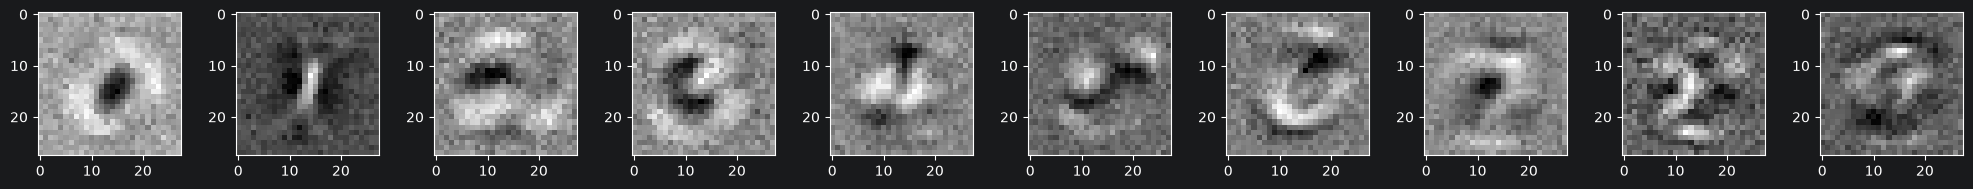

In [23]:
fig, ax = plt.subplots(1, 10, figsize=(20, 2))
for i in range(10):
    ax[i].imshow(W[:, i].detach().view(28, 28), cmap='gray')
    plt.tight_layout()